In [2]:
import pandas as pd
df=pd.read_csv('data/AP001.csv')
df.head()

,From Date,To Date,PM2.5 (ug/m3),PM10 (ug/m3),NO (ug/m3),NO2 (ug/m3),NOx (ppb),NH3 (ug/m3),SO2 (ug/m3),CO (mg/m3),...,Temp (degree C),RH (%),WS (m/s),WD (deg),SR (W/mt2),BP (mmHg),VWS (m/s),Xylene (ug/m3),RF (mm),AT (degree C)
0,2016-07-01 10:00:00,2016-07-01 11:00:00,10.67,39.0,17.67,39.2,32.33,7.07,6.60,0.48,...,33.43,71.67,2.30,226.33,123.67,NaN,-0.1,0.1,0.0,23.05
1,2016-07-01 11:00:00,2016-07-01 12:00:00,2.00,39.0,20.50,41.9,35.80,7.40,NaN,0.49,...,33.70,70.00,2.50,223.00,186.00,NaN,-0.1,0.1,0.0,NaN
2,2016-07-01 12:00:00,2016-07-01 13:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-07-01 13:00:00,2016-07-01 14:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-07-01 14:00:00,2016-07-01 15:00:00,20.50,50.0,15.40,43.6,32.78,6.35,6.38,0.47,...,33.57,63.50,1.88,223.00,240.50,NaN,-0.1,0.1,0.0,NaN


In [4]:

# 1. Convert 'From Date' to datetime and set as index
df['From Date'] = pd.to_datetime(df['From Date'])
df = df.sort_values('From Date').set_index('From Date')

# 2. Drop redundant and mostly empty columns
df = df.drop(columns=['To Date', 'BP (mmHg)'])

print("Index type:", type(df.index))
print("Remaining columns:", len(df.columns))
df.head(3)

Index type: <class 'pandas.DatetimeIndex'>
Remaining columns: 20


,PM2.5 (ug/m3),PM10 (ug/m3),NO (ug/m3),NO2 (ug/m3),NOx (ppb),NH3 (ug/m3),SO2 (ug/m3),CO (mg/m3),Ozone (ug/m3),Benzene (ug/m3),Toluene (ug/m3),Temp (degree C),RH (%),WS (m/s),WD (deg),SR (W/mt2),VWS (m/s),Xylene (ug/m3),RF (mm),AT (degree C)
From Date,,,,,,,,,,,,,,,,,,,,
2016-07-01 10:00:00,10.67,39.0,17.67,39.2,32.33,7.07,6.6,0.48,14.5,1.0,4.63,33.43,71.67,2.3,226.33,123.67,-0.1,0.1,0.0,23.05
2016-07-01 11:00:00,2.00,39.0,20.50,41.9,35.80,7.40,NaN,0.49,15.0,0.7,4.50,33.70,70.00,2.5,223.00,186.00,-0.1,0.1,0.0,NaN
2016-07-01 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 59150 entries, 2016-07-01 10:00:00 to 2023-03-31 23:00:00
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PM2.5 (ug/m3)    54323 non-null  float64
 1   PM10 (ug/m3)     54450 non-null  float64
 2   NO (ug/m3)       55153 non-null  float64
 3   NO2 (ug/m3)      55100 non-null  float64
 4   NOx (ppb)        55315 non-null  float64
 5   NH3 (ug/m3)      53564 non-null  float64
 6   SO2 (ug/m3)      54285 non-null  float64
 7   CO (mg/m3)       54673 non-null  float64
 8   Ozone (ug/m3)    54567 non-null  float64
 9   Benzene (ug/m3)  55213 non-null  float64
 10  Toluene (ug/m3)  55213 non-null  float64
 11  Temp (degree C)  55113 non-null  float64
 12  RH (%)           55281 non-null  float64
 13  WS (m/s)         55299 non-null  float64
 14  WD (deg)         54656 non-null  float64
 15  SR (W/mt2)       54589 non-null  float64
 16  VWS (m/s)        55341 non-null  f

In [7]:
# Exclude VWS (m/s) since downward vertical wind speed is naturally negative
cols_without_vws = [col for col in df.columns if col != 'VWS (m/s)']
df[cols_without_vws] = df[cols_without_vws].where(df[cols_without_vws] >= 0)

In [9]:
# 4. Fill small hourly sensor gaps (up to 6 hours)
df_clean = df.interpolate(method='time', limit=6)

In [10]:
# Compare missing values across ALL columns before and after
comparison = pd.DataFrame({
    'Before': df.isnull().sum(),
    'After': df_clean.isnull().sum()
})
comparison['Filled'] = comparison['Before'] - comparison['After']
print(comparison)

                 Before  After  Filled
PM2.5 (ug/m3)      4827   3243    1584
PM10 (ug/m3)       4700   3423    1277
NO (ug/m3)         3997   3019     978
NO2 (ug/m3)        4050   3050    1000
NOx (ppb)          3835   2942     893
NH3 (ug/m3)        5586   4449    1137
SO2 (ug/m3)        4865   3133    1732
CO (mg/m3)         4477   3549     928
Ozone (ug/m3)      4583   3305    1278
Benzene (ug/m3)    3937   3011     926
Toluene (ug/m3)    3937   3011     926
Temp (degree C)    4037   2990    1047
RH (%)             3869   2969     900
WS (m/s)           3851   2957     894
WD (deg)           4494   3020    1474
SR (W/mt2)         4561   3279    1282
VWS (m/s)          3809   2928     881
Xylene (ug/m3)     3950   3011     939
RF (mm)            3865   2933     932
AT (degree C)      4063   3147     916


In [11]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 59150 entries, 2016-07-01 10:00:00 to 2023-03-31 23:00:00
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PM2.5 (ug/m3)    54323 non-null  float64
 1   PM10 (ug/m3)     54450 non-null  float64
 2   NO (ug/m3)       55153 non-null  float64
 3   NO2 (ug/m3)      55100 non-null  float64
 4   NOx (ppb)        55315 non-null  float64
 5   NH3 (ug/m3)      53564 non-null  float64
 6   SO2 (ug/m3)      54285 non-null  float64
 7   CO (mg/m3)       54673 non-null  float64
 8   Ozone (ug/m3)    54567 non-null  float64
 9   Benzene (ug/m3)  55213 non-null  float64
 10  Toluene (ug/m3)  55213 non-null  float64
 11  Temp (degree C)  55113 non-null  float64
 12  RH (%)           55281 non-null  float64
 13  WS (m/s)         55299 non-null  float64
 14  WD (deg)         54656 non-null  float64
 15  SR (W/mt2)       54589 non-null  float64
 16  VWS (m/s)        55341 non-null  f

In [12]:
# 5. Average all sensors per day, EXCEPT rainfall which should be summed
daily_df = df_clean.resample('D').mean()
daily_df['RF (mm)'] = df_clean['RF (mm)'].resample('D').sum()

print("Original hourly rows:", len(df_clean))
print("New daily rows      :", len(daily_df))
daily_df[['PM2.5 (ug/m3)', 'PM10 (ug/m3)', 'Temp (degree C)', 'RF (mm)']].head()

Original hourly rows: 59150
New daily rows      : 2465


,PM2.5 (ug/m3),PM10 (ug/m3),Temp (degree C),RF (mm)
From Date,,,,
2016-07-01,12.095714,49.892857,33.825714,0.00
2016-07-02,19.537857,61.216905,33.079667,1.37
2016-07-03,14.162500,46.146250,32.721667,4.50
2016-07-04,9.677083,22.793542,32.578750,1.37
2016-07-05,4.718750,17.228750,32.851250,2.08


In [13]:
daily_df['Year']=daily_df.index.year
daily_df['Month']=daily_df.index.month
daily_df['Month_Name']=daily_df.index.strftime('%b')
daily_df['Day_of_Week']=daily_df.index.day_name()

def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    else:
        return 'Post-Monsoon'

daily_df['Season'] = daily_df['Month'].apply(get_season)

daily_df[['Year', 'Month_Name', 'Day_of_Week', 'Season', 'PM2.5 (ug/m3)']].head()

,Year,Month_Name,Day_of_Week,Season,PM2.5 (ug/m3)
From Date,,,,,
2016-07-01,2016,Jul,Friday,Monsoon,12.095714
2016-07-02,2016,Jul,Saturday,Monsoon,19.537857
2016-07-03,2016,Jul,Sunday,Monsoon,14.162500
2016-07-04,2016,Jul,Monday,Monsoon,9.677083
2016-07-05,2016,Jul,Tuesday,Monsoon,4.718750


In [14]:
daily_df.to_csv('data/daily_cleand.csv')

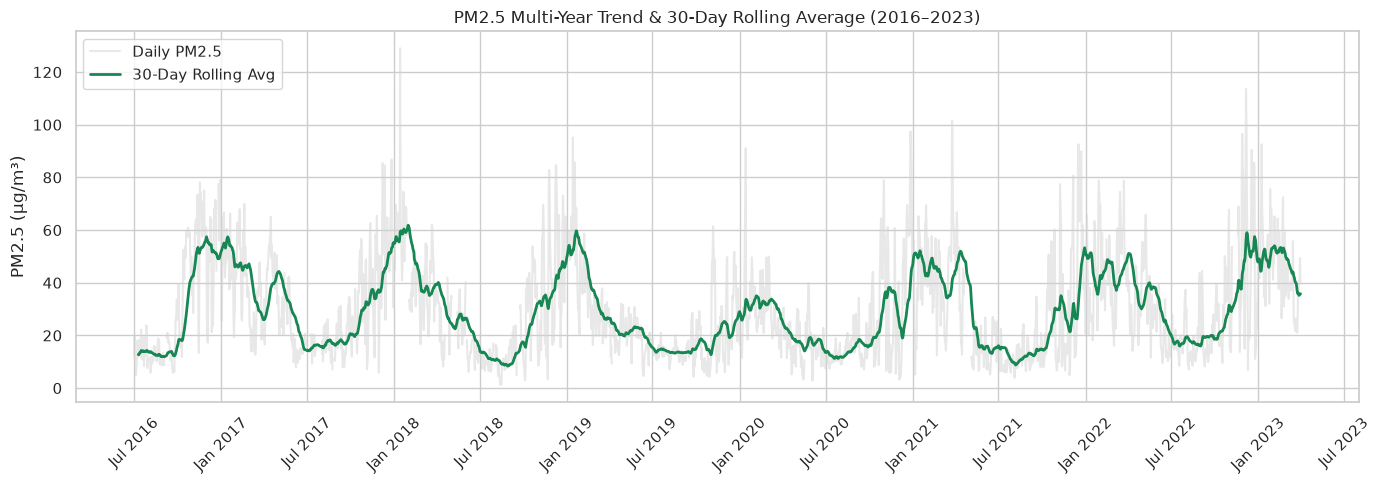

In [18]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(14, 5))
plt.plot(daily_df.index, daily_df['PM2.5 (ug/m3)'], color='lightgray', alpha=0.5, label='Daily PM2.5')
plt.plot(daily_df.index, daily_df['PM2.5_30d'], color='#168653', linewidth=2, label='30-Day Rolling Avg')

ax = plt.gca()
# Major labels every 6 months (Jan and Jul) so you see Winter vs. Monsoon clearly
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# Small tick marks for every single month in between
ax.xaxis.set_minor_locator(mdates.MonthLocator())
plt.xticks(rotation=45)

plt.title('PM2.5 Multi-Year Trend & 30-Day Rolling Average (2016–2023)')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_17276/1575276791.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=daily_df, x='Season', y='PM2.5 (ug/m3)', order=season_order, palette='Set2')


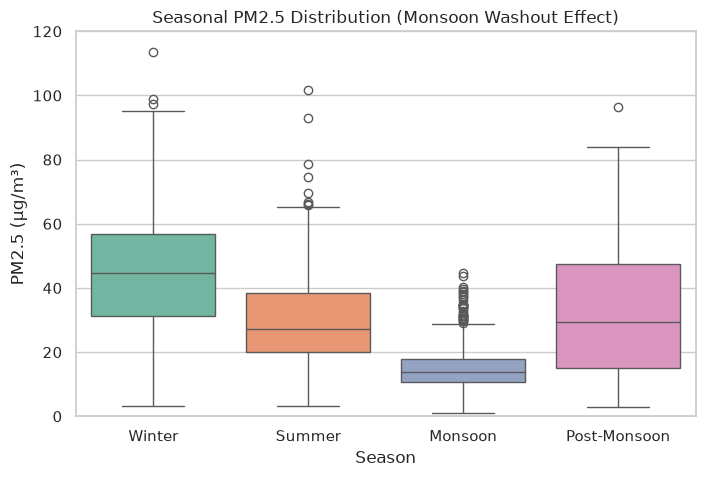

In [16]:
plt.figure(figsize=(8, 5))
season_order = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']

sns.boxplot(data=daily_df, x='Season', y='PM2.5 (ug/m3)', order=season_order, palette='Set2')
plt.title('Seasonal PM2.5 Distribution (Monsoon Washout Effect)')
plt.ylabel('PM2.5 (µg/m³)')
plt.ylim(0, 120)  # Zooms in on 0–120 so extreme outliers don't squish the boxes
plt.show()

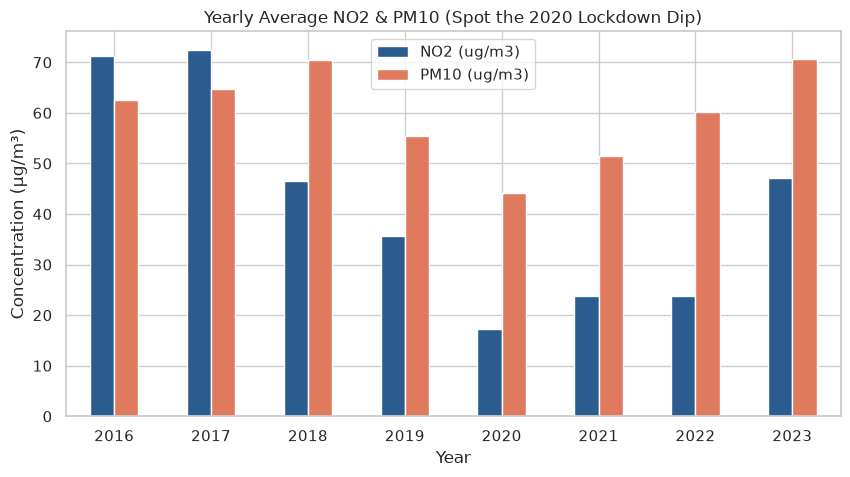

In [19]:
yearly_avg = daily_df.groupby('Year')[['NO2 (ug/m3)', 'PM10 (ug/m3)']].mean()

yearly_avg.plot(kind='bar', figsize=(10, 5), color=['#2b5c8f', '#e07a5f'])
plt.title('Yearly Average NO2 & PM10 (Spot the 2020 Lockdown Dip)')
plt.ylabel('Concentration (µg/m³)')
plt.xticks(rotation=0)  # Keeps year labels horizontal instead of tilted
plt.show()

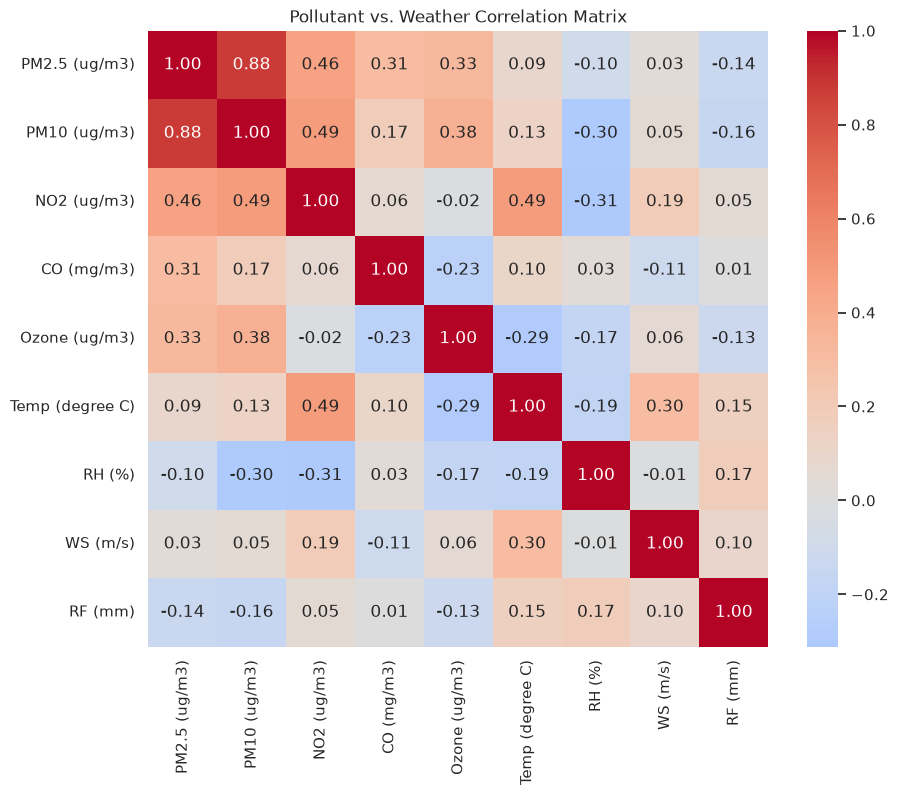

In [20]:
plt.figure(figsize=(10, 8))
cols = ['PM2.5 (ug/m3)', 'PM10 (ug/m3)', 'NO2 (ug/m3)', 'CO (mg/m3)', 'Ozone (ug/m3)', 
        'Temp (degree C)', 'RH (%)', 'WS (m/s)', 'RF (mm)']

corr = daily_df[cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Pollutant vs. Weather Correlation Matrix')
plt.show()